In [1]:
import json
import sys

# Librerías de terceros
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

sys.path.append("..")
from src.preprocesamiento import cargar_datos_procesados, columnas_entrada, particion_temporal

In [2]:
df = cargar_datos_procesados()
df.shape

(193050, 88)

In [3]:
# Partición temporal compartida con la red neuronal y con la Parte 2
particion = particion_temporal(df["issue_d"])

print(f"Total de registros: {len(df)}")
for nombre, clave in [("entrenamiento", "train"), ("validación", "val"), ("prueba", "test")]:
    parte = df[particion == clave]
    print(f"El conjunto de {nombre} va desde: {parte['issue_d'].min():%Y-%m} hasta {parte['issue_d'].max():%Y-%m}")

Total de registros: 193050
El conjunto de entrenamiento va desde: 2012-08 hasta 2014-04
El conjunto de validación va desde: 2014-05 hasta 2014-10
El conjunto de prueba va desde: 2014-11 hasta 2015-12


In [4]:
features = columnas_entrada(df)

X = df[features]
y = df["incumple"]

X_train, y_train = X[particion == "train"], y[particion == "train"]
X_val,   y_val   = X[particion == "val"],   y[particion == "val"]
X_test,  y_test  = X[particion == "test"],  y[particion == "test"]

print(f"Train temporal: {X_train.shape} | Val temporal: {X_val.shape} | Test temporal: {X_test.shape}")

Train temporal: (118372, 82) | Val temporal: (38300, 82) | Test temporal: (36378, 82)


In [5]:
print("Distribución de la variable respuesta en los datos de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Distribución de la variable respuesta en los datos de validación:")
print(y_val.value_counts(normalize=True))

Distribución de la variable respuesta en los datos de entrenamiento:
incumple
0    0.782939
1    0.217061
Name: proportion, dtype: float64


Distribución de la variable respuesta en los datos de validación:
incumple
0    0.735875
1    0.264125
Name: proportion, dtype: float64


In [6]:
# Selecciona GPU si está disponible, de lo contrario usa CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo que se está utilizando
print(f"Usando: {device}")

Usando: cpu


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_val)

In [8]:
modelo = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train_scaled, y_train)
print("\nModelo entrenado ✓")

C:\Users\Usuario\Documents\GitHub\RedesNeuronales_Trabajo2\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



Modelo entrenado ✓


In [9]:
y_pred = modelo.predict(X_test_scaled)
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

In [10]:
print("\n── Classification Report ──────────────────────────────────")
print(classification_report(y_val, y_pred,
                             target_names=["No Default (0)", "Default (1)"]))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")


── Classification Report ──────────────────────────────────
                precision    recall  f1-score   support

No Default (0)       0.84      0.66      0.74     28184
   Default (1)       0.40      0.64      0.50     10116

      accuracy                           0.65     38300
     macro avg       0.62      0.65      0.62     38300
  weighted avg       0.72      0.65      0.67     38300

ROC-AUC: 0.7100


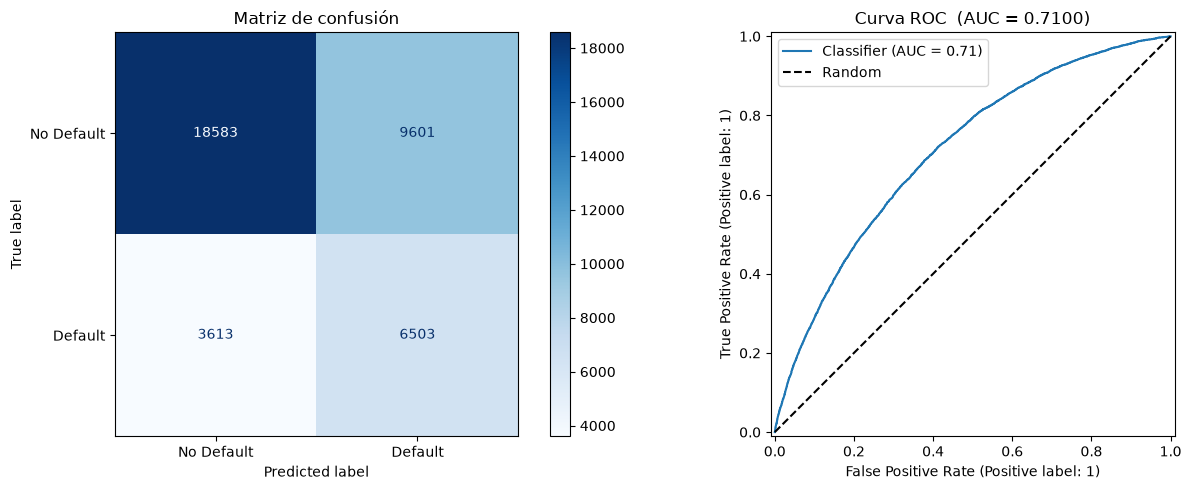

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión")

# Curva ROC
RocCurveDisplay.from_predictions(y_val, y_prob, ax=axes[1])
axes[1].set_title(f"Curva ROC  (AUC = {roc_auc_score(y_val, y_prob):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].legend()

plt.tight_layout()
plt.show()


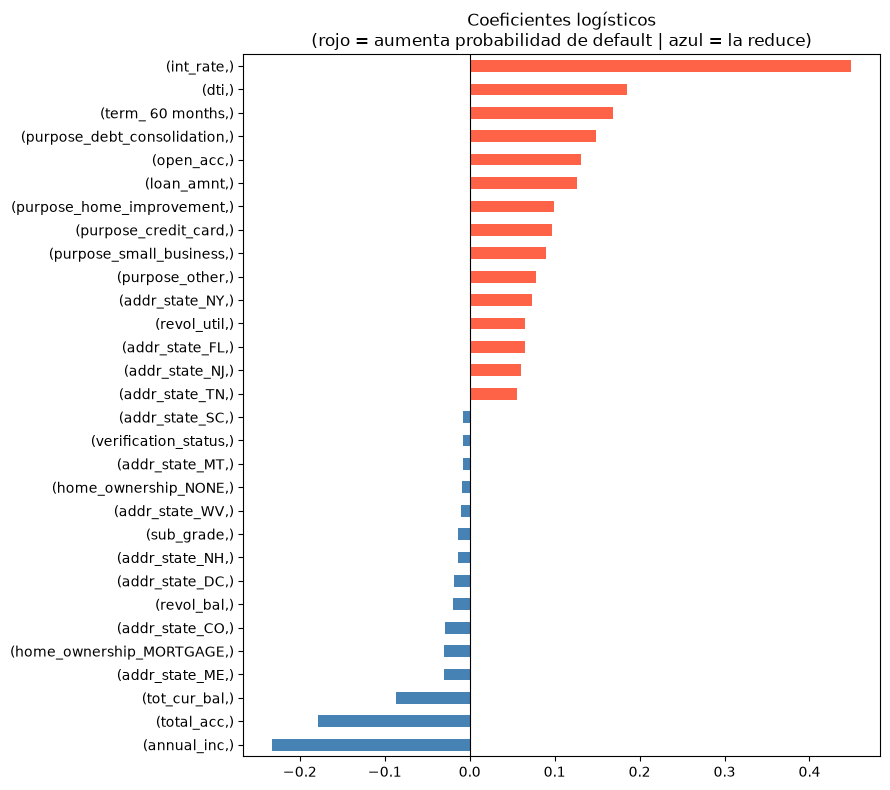


Top 10 variables que MÁS aumentan default:
int_rate                      0.448954
dti                           0.185065
term_ 60 months               0.169215
purpose_debt_consolidation    0.148446
open_acc                      0.130673
loan_amnt                     0.126323
purpose_home_improvement      0.099817
purpose_credit_card           0.096788
purpose_small_business        0.090242
purpose_other                 0.077541

Top 10 variables que MÁS reducen default:
sub_grade                 -0.013415
addr_state_NH             -0.013516
addr_state_DC             -0.019000
revol_bal                 -0.019816
addr_state_CO             -0.028491
home_ownership_MORTGAGE   -0.030488
addr_state_ME             -0.030703
tot_cur_bal               -0.086201
total_acc                 -0.178380
annual_inc                -0.232250


In [12]:
coeficientes = pd.Series(
    modelo.coef_[0],
    index=[X.columns]
).sort_values(ascending=False)

# Top 15 positivos y negativos
top_n = 15
top_coefs = pd.concat([
    coeficientes.head(top_n),
    coeficientes.tail(top_n)
]).sort_values()

colores = ["steelblue" if v < 0 else "tomato" for v in top_coefs]

top_coefs.plot(kind="barh", figsize=(9, 8), color=colores)
plt.title("Coeficientes logísticos\n"
          "(rojo = aumenta probabilidad de default | "
          "azul = la reduce)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nTop 10 variables que MÁS aumentan default:")
print(coeficientes.head(10).to_string())

print("\nTop 10 variables que MÁS reducen default:")
print(coeficientes.tail(10).to_string())
